# 1. Cargo el dataset especificando que el separador es punto y coma ';'

In [9]:
import pandas as pd

# 1. Cargo el dataset especificando que el separador es punto y coma ';'
df = pd.read_csv("/content/obs_salud_sexual_reproductiva-mortalidadc_ii_semestre.csv", sep=';')

# 2. Eliminar columnas que estén completamente vacías o sin nombre (debido a los ';' extras al final de las líneas)

In [4]:
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]
df = df.dropna(how='all', axis=1)


# 3. Revise los valores nulos y duplicados


In [5]:
print("--- VALORES NULOS POR COLUMNA ---")
print(df.isnull().sum())
print("\n--- VALORES DUPLICADOS ---")
print(df.duplicated().sum())



--- VALORES NULOS POR COLUMNA ---
Año;Localidad;Muertes;Denominador poblacional;Tasa por 100.000 menores de 5 años;;;    26
dtype: int64

--- VALORES DUPLICADOS ---
162


# 4. Limpieza de la columna 'Tasa por 100.000 menores de 5 años' (cambiar coma por punto para convertir a numérico)


In [15]:
if 'Tasa por 100.000 menores de 5\' años' in df.columns:
    col_name = 'Tasa por 100.000 menores de 5\' años'
elif 'Tasa por 100.000 menores de 5 años' in df.columns:
    col_name = 'Tasa por 100.000 menores de 5 años'
else:
    col_name = [c for c in df.columns if 'Tasa' in c][0]

df[col_name] = df[col_name].astype(str).str.replace(',', '.').astype(float)



# 5. Vista previa del resultado limpio


In [14]:
print("\n--- PRIMERAS FILAS DEL DATAFRAME LIMPIO ---")
print(df.head())




--- PRIMERAS FILAS DEL DATAFRAME LIMPIO ---
    Año      Localidad  Muertes  Denominador poblacional  \
0  2015         Bogotá      294                  484.506   
1  2015        Usaquén       18                   28.764   
2  2015      Chapinero        6                    7.623   
3  2015       Santa Fe        2                    6.961   
4  2015  San Cristóbal       25                   28.900   

   Tasa por 100.000 menores de 5 años  Unnamed: 5  Unnamed: 6  Unnamed: 7  
0                               60.68         NaN         NaN         NaN  
1                               62.58         NaN         NaN         NaN  
2                               78.71         NaN         NaN         NaN  
3                               28.73         NaN         NaN         NaN  
4                               86.51         NaN         NaN         NaN  


EDA (Analisis exploratorio de datos)



# Obtener estadísticas clave del dataset limpio



In [20]:
print(df.describe())


          Muertes  Denominador poblacional  \
count  254.000000               254.000000   
mean    18.704724                85.641421   
std     43.652004               174.450477   
min      0.000000                 0.000000   
25%      2.250000                 7.800000   
50%      7.000000                25.516000   
75%     17.000000                52.079750   
max    294.000000               761.000000   

       Tasa por 100.000 menores de 5 años  Unnamed: 5  Unnamed: 6  Unnamed: 7  
count                          254.000000         0.0         0.0         0.0  
mean                            47.131024         NaN         NaN         NaN  
std                             62.909065         NaN         NaN         NaN  
min                              0.000000         NaN         NaN         NaN  
25%                             24.840000         NaN         NaN         NaN  
50%                             40.740000         NaN         NaN         NaN  
75%                      

## Generare los graficos que visualizan como se relacionan las variables

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns


# Configurar el estilo de los gráficos

In [22]:
sns.set_theme(style="whitegrid")


# Gráfico 1: Histograma y KDE de la Tasa de Mortalidad

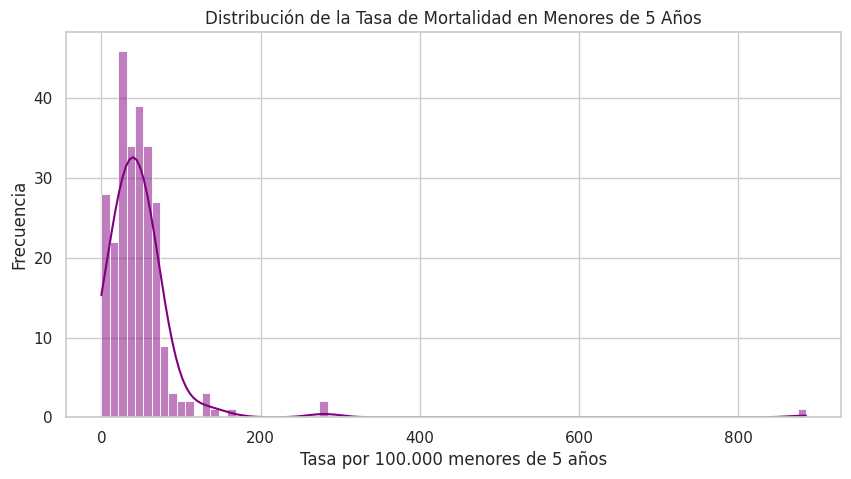

In [23]:
plt.figure(figsize=(10, 5))
sns.histplot(df['Tasa por 100.000 menores de 5 años'], kde=True, color='purple')
plt.title('Distribución de la Tasa de Mortalidad en Menores de 5 Años')
plt.xlabel('Tasa por 100.000 menores de 5 años')
plt.ylabel('Frecuencia')
plt.show()


# Gráfico 2: Top 5 de Localidades con más muertes acumuladas (excluyendo el total de Bogotá)

/tmp/ipykernel_3313/201021131.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_localidades, x='Localidad', y='Muertes', palette='viridis')


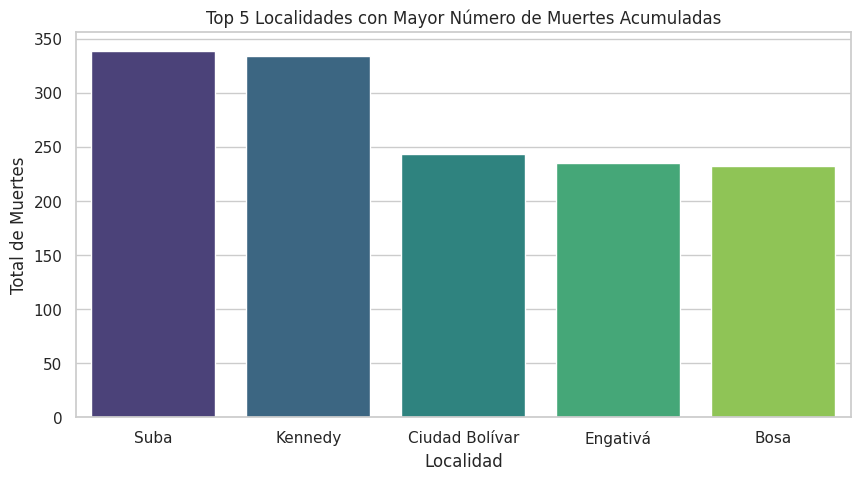

In [24]:
df_localidades = df[~df['Localidad'].isin(['Bogotá', 'Sin Dato', 'Sin información'])]
top_localidades = df_localidades.groupby('Localidad')['Muertes'].sum().reset_index().sort_values(by='Muertes', ascending=False).head(5)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_localidades, x='Localidad', y='Muertes', palette='viridis')
plt.title('Top 5 Localidades con Mayor Número de Muertes Acumuladas')
plt.xlabel('Localidad')
plt.ylabel('Total de Muertes')
plt.show()


```markdown
## # 7. Exportar y Descargar el Dataset Limpio
Ejecuta la siguiente celda para guardar tus datos limpios en un nuevo archivo CSV y descargarlo automáticamente.
```

In [25]:
from google.colab import files

# Guardamos el DataFrame limpio a un nuevo archivo CSV sin los índices
df.to_csv('mortalidad_limpio.csv', index=False, sep=';')

# Descargamos el archivo directamente a tu computadora
files.download('mortalidad_limpio.csv')
print("¡El archivo 'mortalidad_limpio.csv' se ha exportado y se descargará en breve!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

¡El archivo 'mortalidad_limpio.csv' se ha exportado y se descargará en breve!
